# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils import *

## Load Data

Load data and select features with an SQL query through the duckdb.

Based on the EDA results, `year`, `patch`, and `gamelength` are removed because they have 0.00 correlation with the target variable `result`.
On the other hand, `towers`, `assists`, `assistsatX`, `goldspent`, `opp_deathsatX`, `golddiffat20`, and `xpdiffat20` are removed because they have high correlation with other variables, which may cause multicollinearity during modeling. This also applies to stats at the 25th minute mark as they correlate high with the stats at the 20th minute mark.

In [2]:
# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'split', 'date', 'teamname',
                   'result', 'kills', 'deaths', 'dpm', 
                   'damagetakenperminute', 'wardskilled', 'totalgold',
                   'firstdragon', 'firstbaron', 'barons', 'opp_barons',
                   'golddiffat10', 'xpdiffat10', 'killsat10', 'opp_killsat10',
                   'golddiffat15', 'xpdiffat15', 'killsat15', 'opp_killsat15',
                   'killsat20', 'opp_killsat20'
                   ]

db = 'lol_predictors.duckdb'
df_selected = "df_2014" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include, db)

## Data Cleaning

For **data imputation**, only the feature `split` has missing values based on df_2014's EDA. We can use the previous value for each NaN since there's only two values, which are `Summer` and `Spring`, and they are sorted chronologically.

In [3]:
df['split'] = df['split'].ffill()

We will **trim outliers** because even the feature `wardskilled` that has the highest outlier percentage only has `<2%` of outliers.

In [4]:
num_cols = df.select_dtypes(include=["number"]).columns.tolist()

print(num_cols)

for col in num_cols:
    df = df[~detect_outliers(df, col).to_numpy()]

['result', 'kills', 'deaths', 'dpm', 'damagetakenperminute', 'wardskilled', 'totalgold', 'firstdragon', 'firstbaron', 'barons', 'opp_barons', 'golddiffat10', 'xpdiffat10', 'killsat10', 'opp_killsat10', 'golddiffat15', 'xpdiffat15', 'killsat15', 'opp_killsat15', 'killsat20', 'opp_killsat20']


This concludes data cleaning of df_2014, which is the Lol Esports data on 2014 based on Oracle's Elixir. From the EDA, there are no categories in categorical features that needs fixing. 

## Post-Processing Data Audit

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 1489 entries, 0 to 1835
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                1489 non-null   str    
 1   league                1489 non-null   str    
 2   split                 1489 non-null   str    
 3   date                  1489 non-null   str    
 4   teamname              1489 non-null   str    
 5   result                1489 non-null   int64  
 6   kills                 1489 non-null   int64  
 7   deaths                1489 non-null   int64  
 8   dpm                   1489 non-null   float64
 9   damagetakenperminute  1489 non-null   float64
 10  wardskilled           1489 non-null   int64  
 11  totalgold             1489 non-null   int64  
 12  firstdragon           1489 non-null   float64
 13  firstbaron            1489 non-null   float64
 14  barons                1489 non-null   float64
 15  opp_barons            1489 non-null  

In [6]:
df.shape

(1489, 26)

In [7]:
display(df.describe())

,result,kills,deaths,dpm,damagetakenperminute,wardskilled,totalgold,firstdragon,firstbaron,barons,...,golddiffat10,xpdiffat10,killsat10,opp_killsat10,golddiffat15,xpdiffat15,killsat15,opp_killsat15,killsat20,opp_killsat20
count,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,...,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000,1489.000000
mean,0.497649,12.821357,12.882471,1864.964025,2659.174240,26.494963,60822.922767,0.498993,0.470114,0.688381,...,-7.148422,-8.275353,1.151780,1.157152,-10.823371,-11.639355,2.595030,2.601746,4.425118,4.435863
std,0.500162,6.837814,6.868897,434.244626,430.968458,12.031997,13934.272734,0.500167,0.499274,0.724666,...,1128.979940,1031.568086,1.178805,1.180380,2431.587118,1848.906329,1.893467,1.895601,2.757188,2.763302
min,0.000000,0.000000,0.000000,708.806500,1491.435000,2.000000,26280.000000,0.000000,0.000000,0.000000,...,-3021.000000,-2877.000000,0.000000,0.000000,-7122.000000,-5271.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,7.000000,7.000000,1561.058300,2360.079600,18.000000,50750.000000,0.000000,0.000000,0.000000,...,-737.000000,-709.000000,0.000000,0.000000,-1744.000000,-1296.000000,1.000000,1.000000,2.000000,2.000000
50%,0.000000,13.000000,13.000000,1861.113200,2655.963700,25.000000,60786.000000,0.000000,0.000000,1.000000,...,-9.000000,-12.000000,1.000000,1.000000,-18.000000,-13.000000,2.000000,2.000000,4.000000,4.000000
75%,1.000000,18.000000,18.000000,2167.015800,2960.561000,34.000000,70562.000000,1.000000,1.000000,1.000000,...,726.000000,685.000000,2.000000,2.000000,1721.000000,1281.000000,4.000000,4.000000,6.000000,6.000000
max,1.000000,34.000000,34.000000,3076.483700,3862.937600,59.000000,100425.000000,1.000000,1.000000,2.000000,...,3021.000000,2877.000000,5.000000,5.000000,7122.000000,5271.000000,8.000000,8.000000,12.000000,12.000000


In [8]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'split', 'teamname', 'result', 'kills', 'deaths',
       'dpm', 'damagetakenperminute', 'wardskilled', 'totalgold',
       'firstdragon', 'firstbaron', 'barons', 'opp_barons', 'golddiffat10',
       'xpdiffat10', 'killsat10', 'opp_killsat10', 'golddiffat15',
       'xpdiffat15', 'killsat15', 'opp_killsat15', 'killsat20',
       'opp_killsat20'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                  0
league                  0
split                   0
teamname                0
result                  0
kills                   0
deaths                  0
dpm                     0
damagetakenperminute    0
wardskilled             0
totalgold               0
firstdragon             0
firstbaron              0
barons                  0
opp_barons              0
golddiffat10            0
xpdiffat10              0
killsat10               0
opp_killsat10           0
golddiffat15            0
xpdiffat15              0
killsat15               0
opp_killsat15           0
killsat20               0
opp_killsat20           0
dtype: int64


------------- COUNT OF UNIQUE VALUES -------------


gameid                   754
league                     5
split                      2
teamname                  78
result                     2
kills                     35
deaths                    35
dpm                     1489
damagetakenperminute    1488
wardskilled               58
totalgold               1468
firstdragon                2
firstbaron                 2
barons                     3
opp_barons                 3
golddiffat10            1277
xpdiffat10              1230
killsat10                  6
opp_killsat10              6
golddiffat15            1379
xpdiffat15              1334
killsat15                  9
opp_killsat15              9
killsat20                 13
opp_killsat20             13
dtype: int64


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
EU LCS    560
NA LCS    547
EU CS     136
NA CS     133
WLDs      113
Name: count, dtype: int64

 split
Spring    847
Summer    642
Name: count, dtype: int64

 teamname
Alliance                 73
TSM                      71
Fnatic                   68
SK Gaming                67
Cloud9                   66
Team ROCCAT              65
Team Curse               63
Team Coast               62
Counter Logic Gaming     61
Dignitas                 59
Copenhagen Wolves        58
Millenium                58
Gambit Gaming            56
SUPA HOT CREW            54
Evil Geniuses            52
LMQ                      52
Curse Academy            36
Ninjas in Pyjamas        32
Reason Gaming            30
XDG Gaming               29
H2k-Gaming               23
compLexity Gaming        22
SK Gaming Prime          20
Team 8                   19
compLexity.Black         16
Gamers2                  16
Royal Club               16
Team LoLPro   

In [9]:
# Limit numerical columns for description and visualization
numcols_to_drop = ['result', 'firstbaron', 'firstdragon']

# Limit categorical columns for description and visualization
catcols_to_drop = ['gameid', 'teamname']

In [10]:
count_outliers(df, numcols_to_drop)


--------------- COUNT OF OUTLIERS ----------------
kills:                      0 (0.00%)
deaths:                     0 (0.00%)
dpm:                        1 (0.07%)
damagetakenperminute:       1 (0.07%)
wardskilled:                6 (0.40%)
totalgold:                  1 (0.07%)
barons:                     0 (0.00%)
opp_barons:                 0 (0.00%)
golddiffat10:               2 (0.13%)
xpdiffat10:                 9 (0.60%)
killsat10:                  0 (0.00%)
opp_killsat10:              0 (0.00%)
golddiffat15:               2 (0.13%)
xpdiffat15:                 3 (0.20%)
killsat15:                  0 (0.00%)
opp_killsat15:              0 (0.00%)
killsat20:                  0 (0.00%)
opp_killsat20:              0 (0.00%)


*Note that the IQR bounds are dynamically recalculated on each call. These remaining outliers are relative to the newly trimmed distribution. Since the new percentage of outliers is < 1%, it is negligible and safe to retain.*

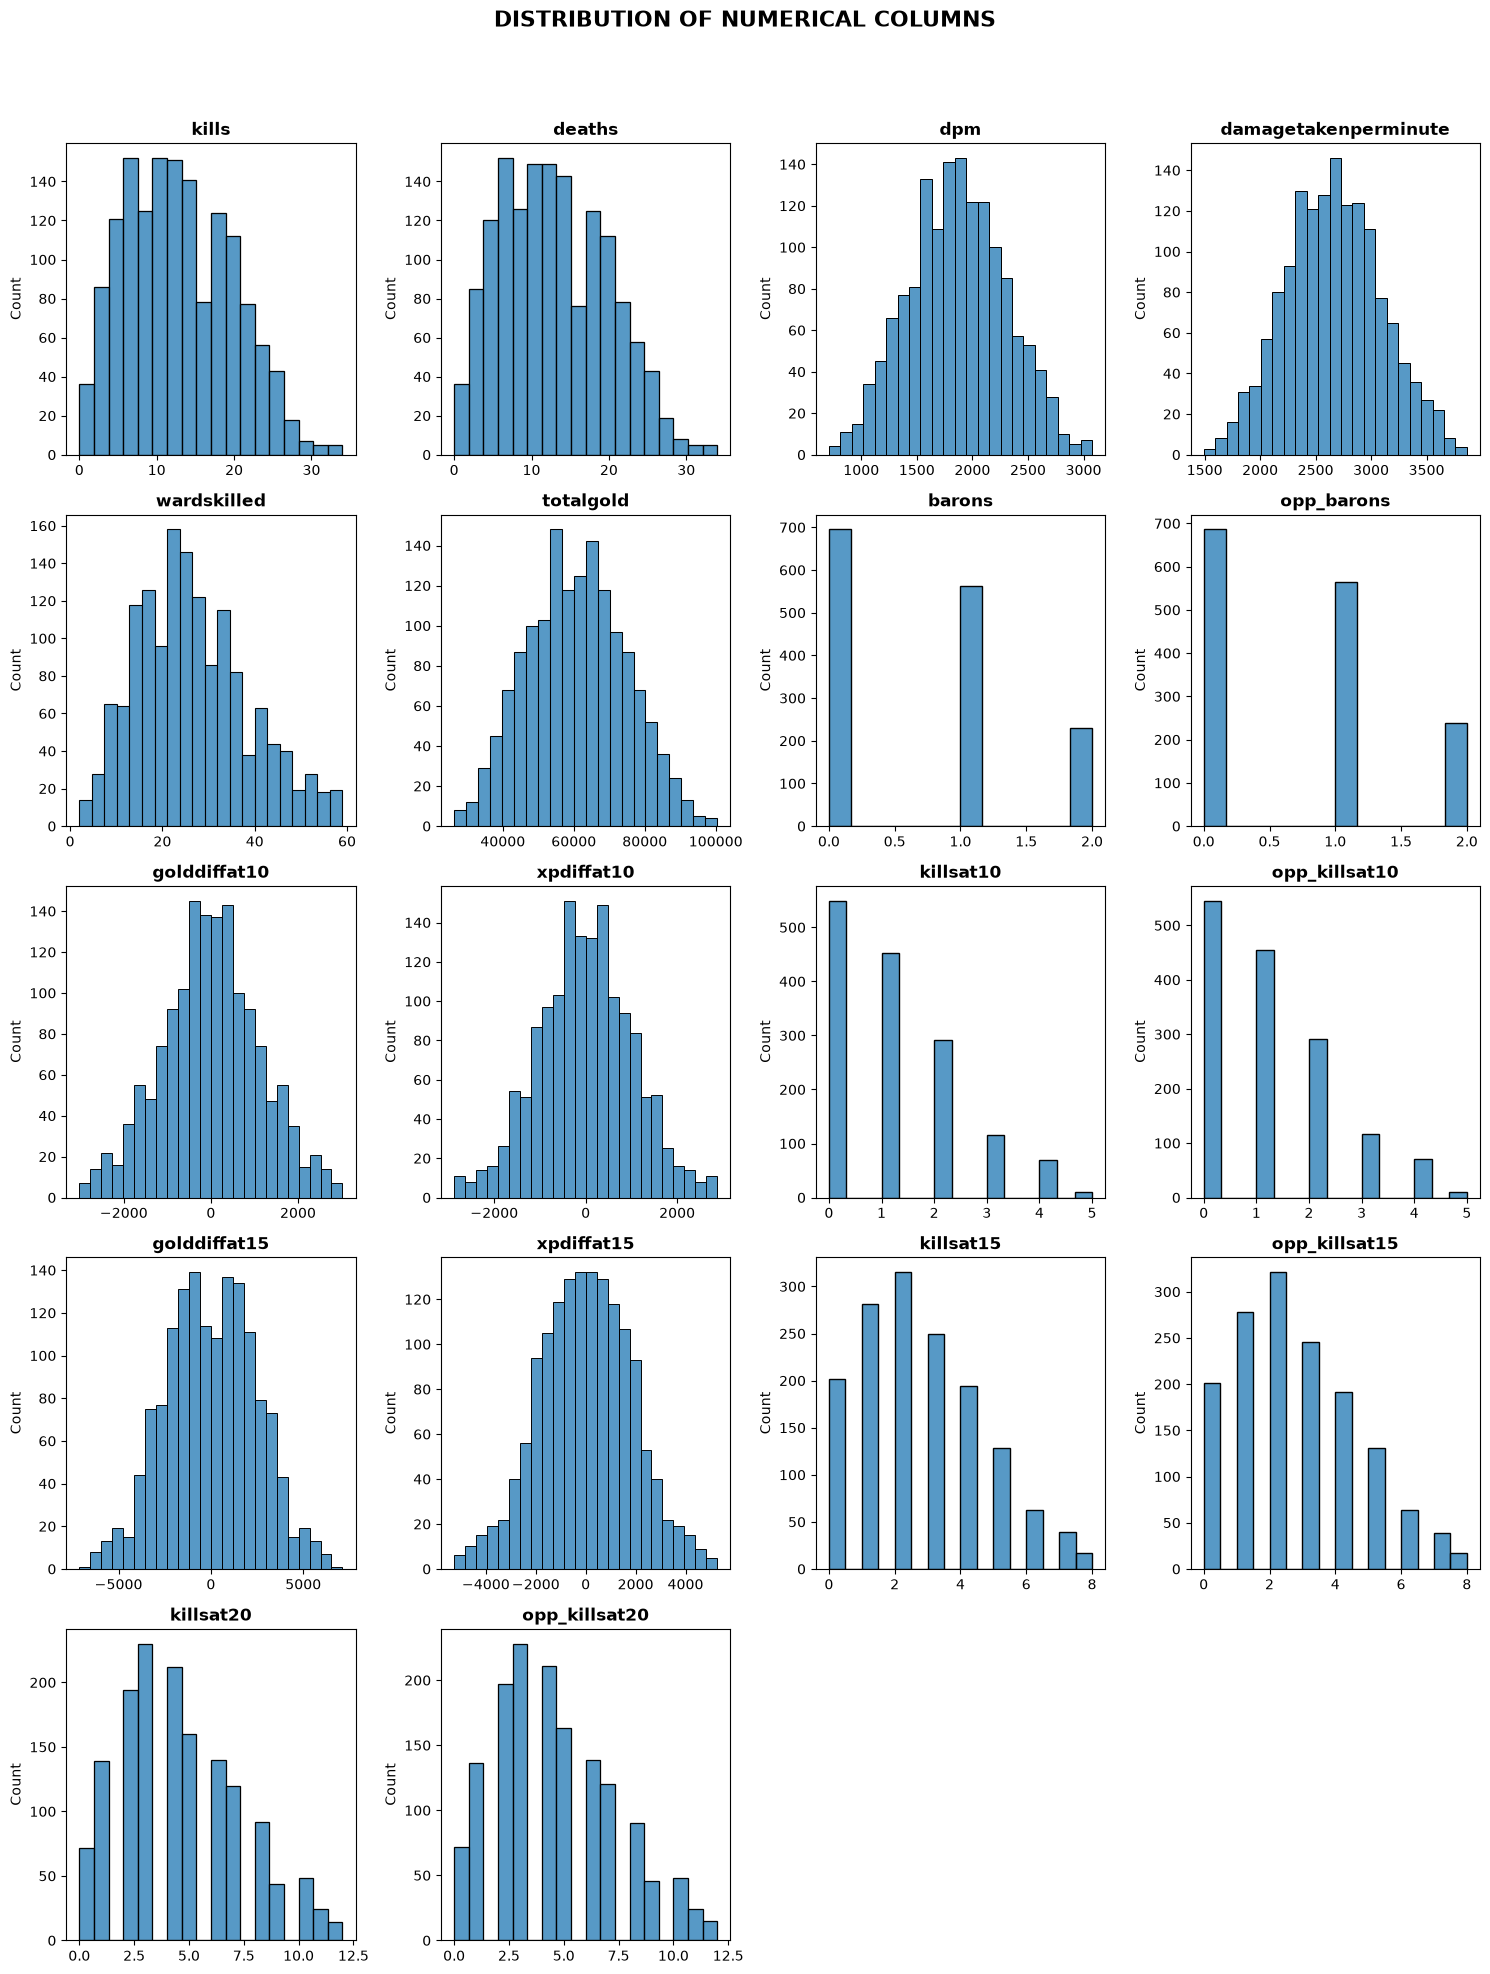

In [11]:
visualize_num_distribution(df, numcols_to_drop, nrows=8, ncols=4, figsize=(15, 30))

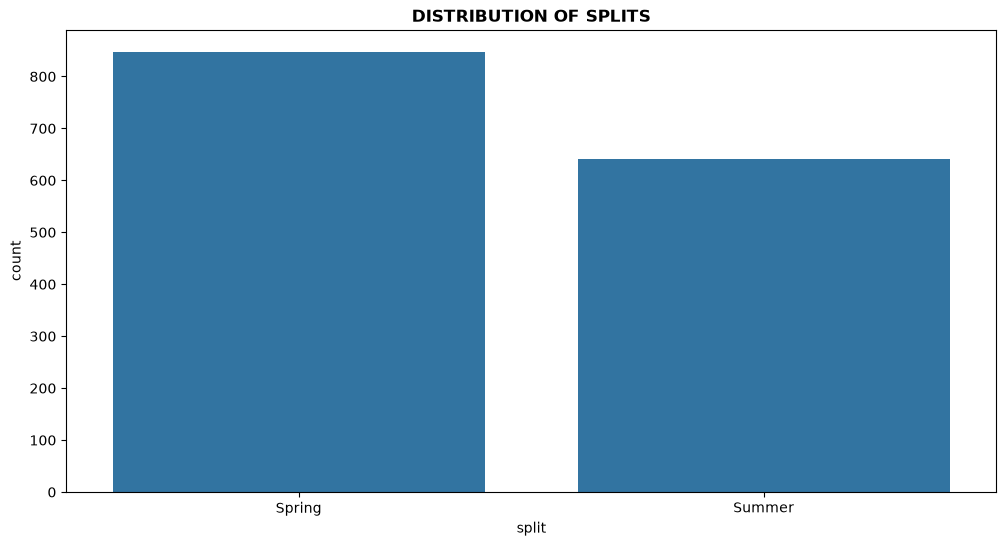

In [12]:
# Visualization of the Splits Distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='split')
plt.title('DISTRIBUTION OF SPLITS', fontsize=12, fontweight="bold")
plt.show()

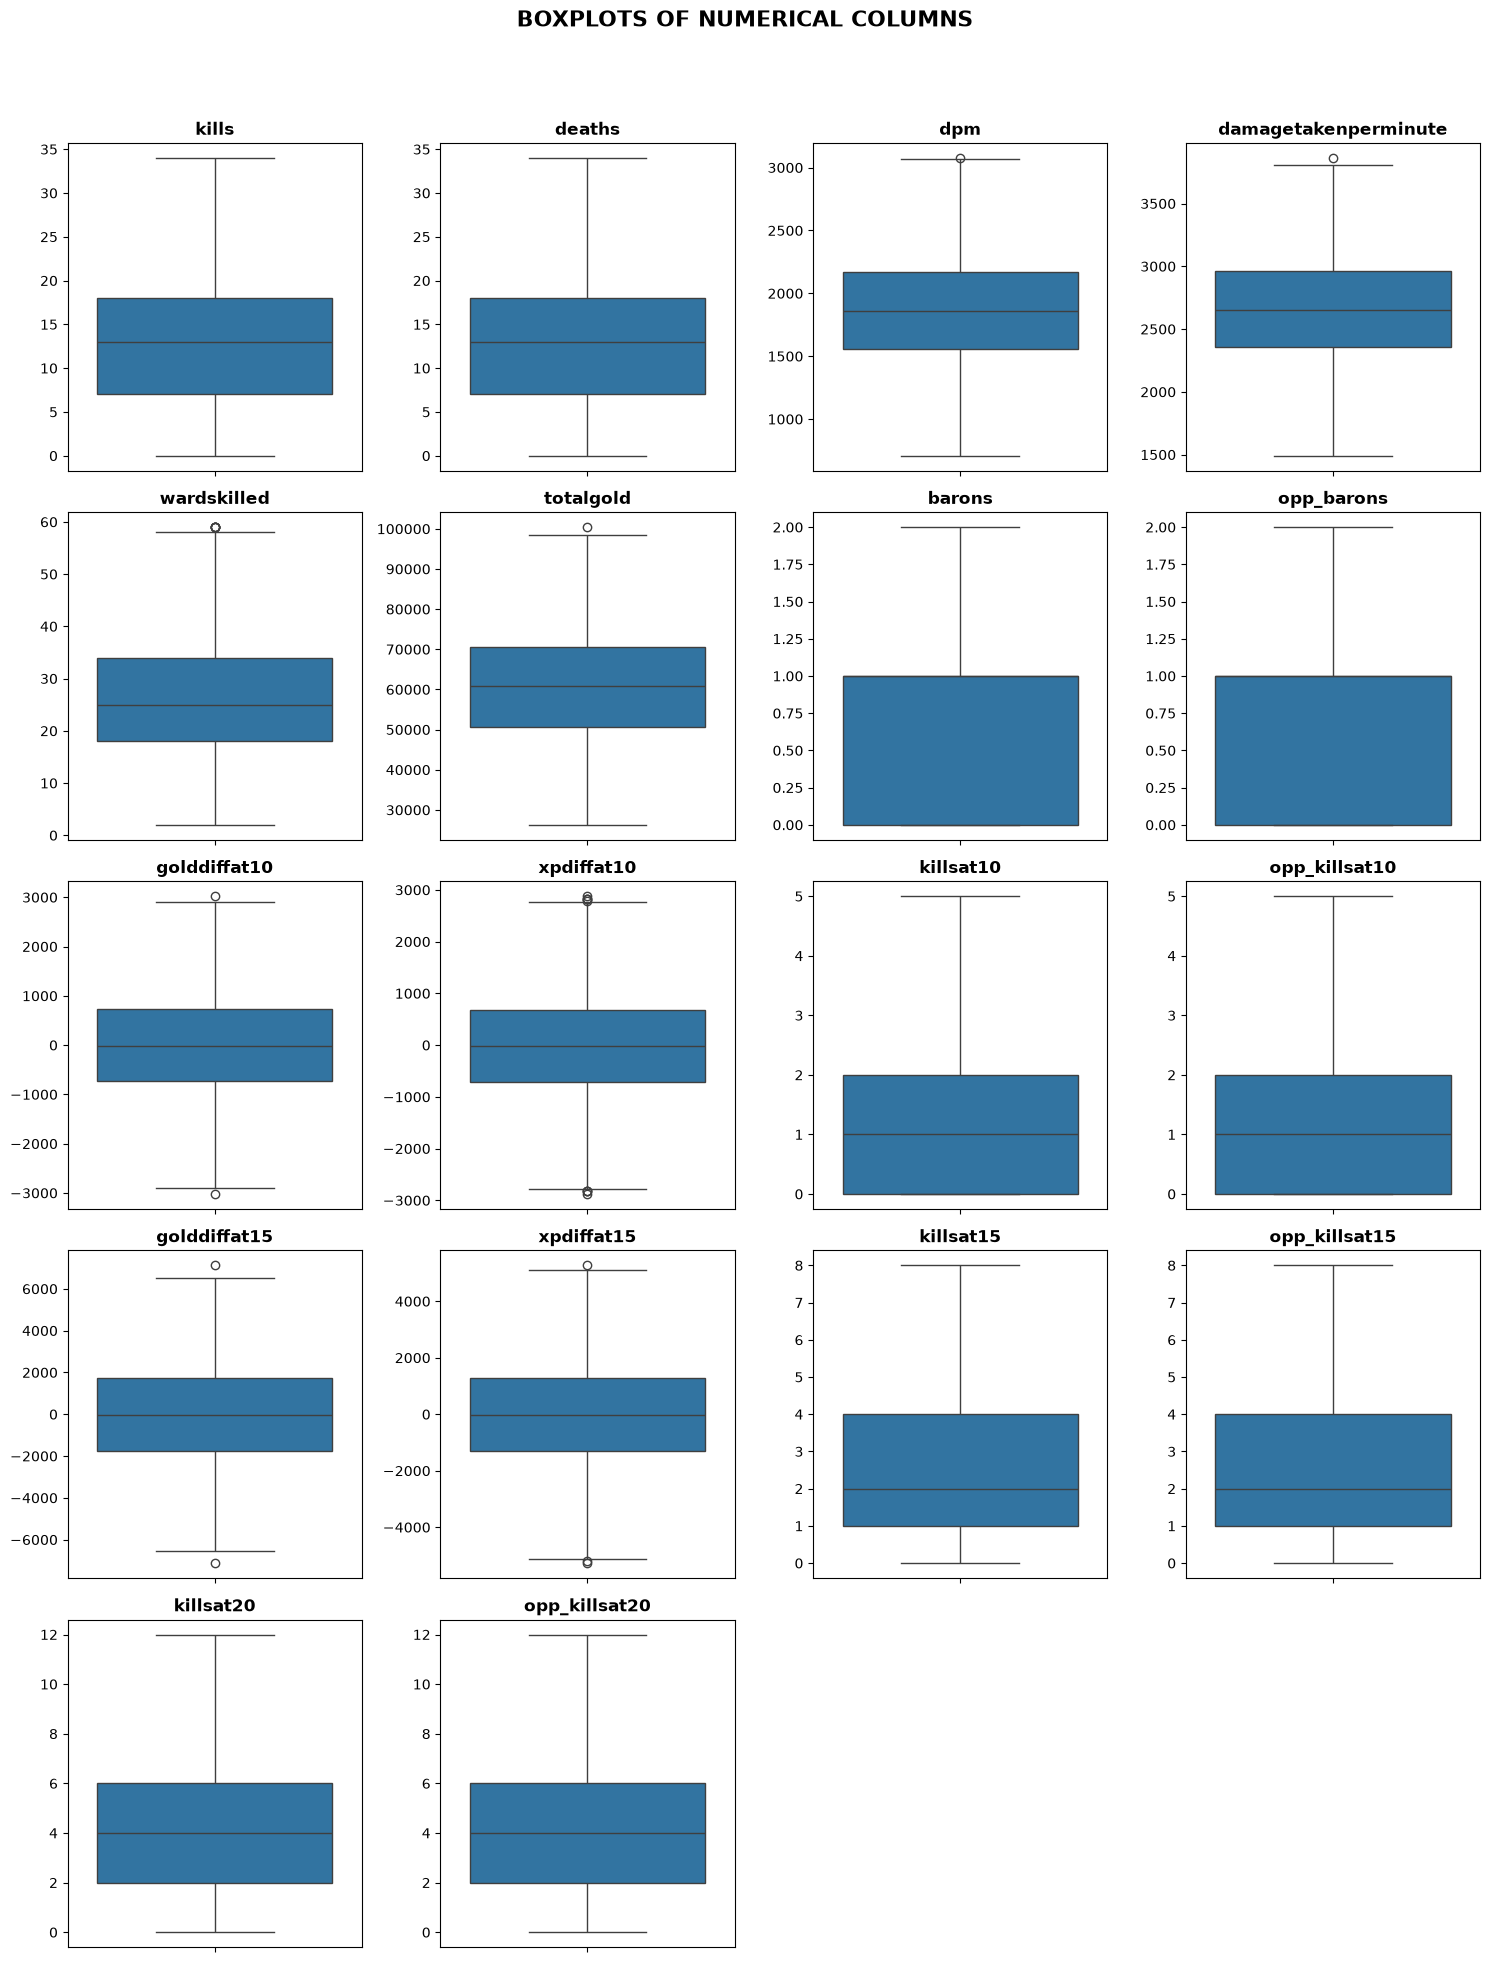

In [13]:
visualize_outliers(df, numcols_to_drop, nrows=8, ncols=4, figsize=(15, 30))

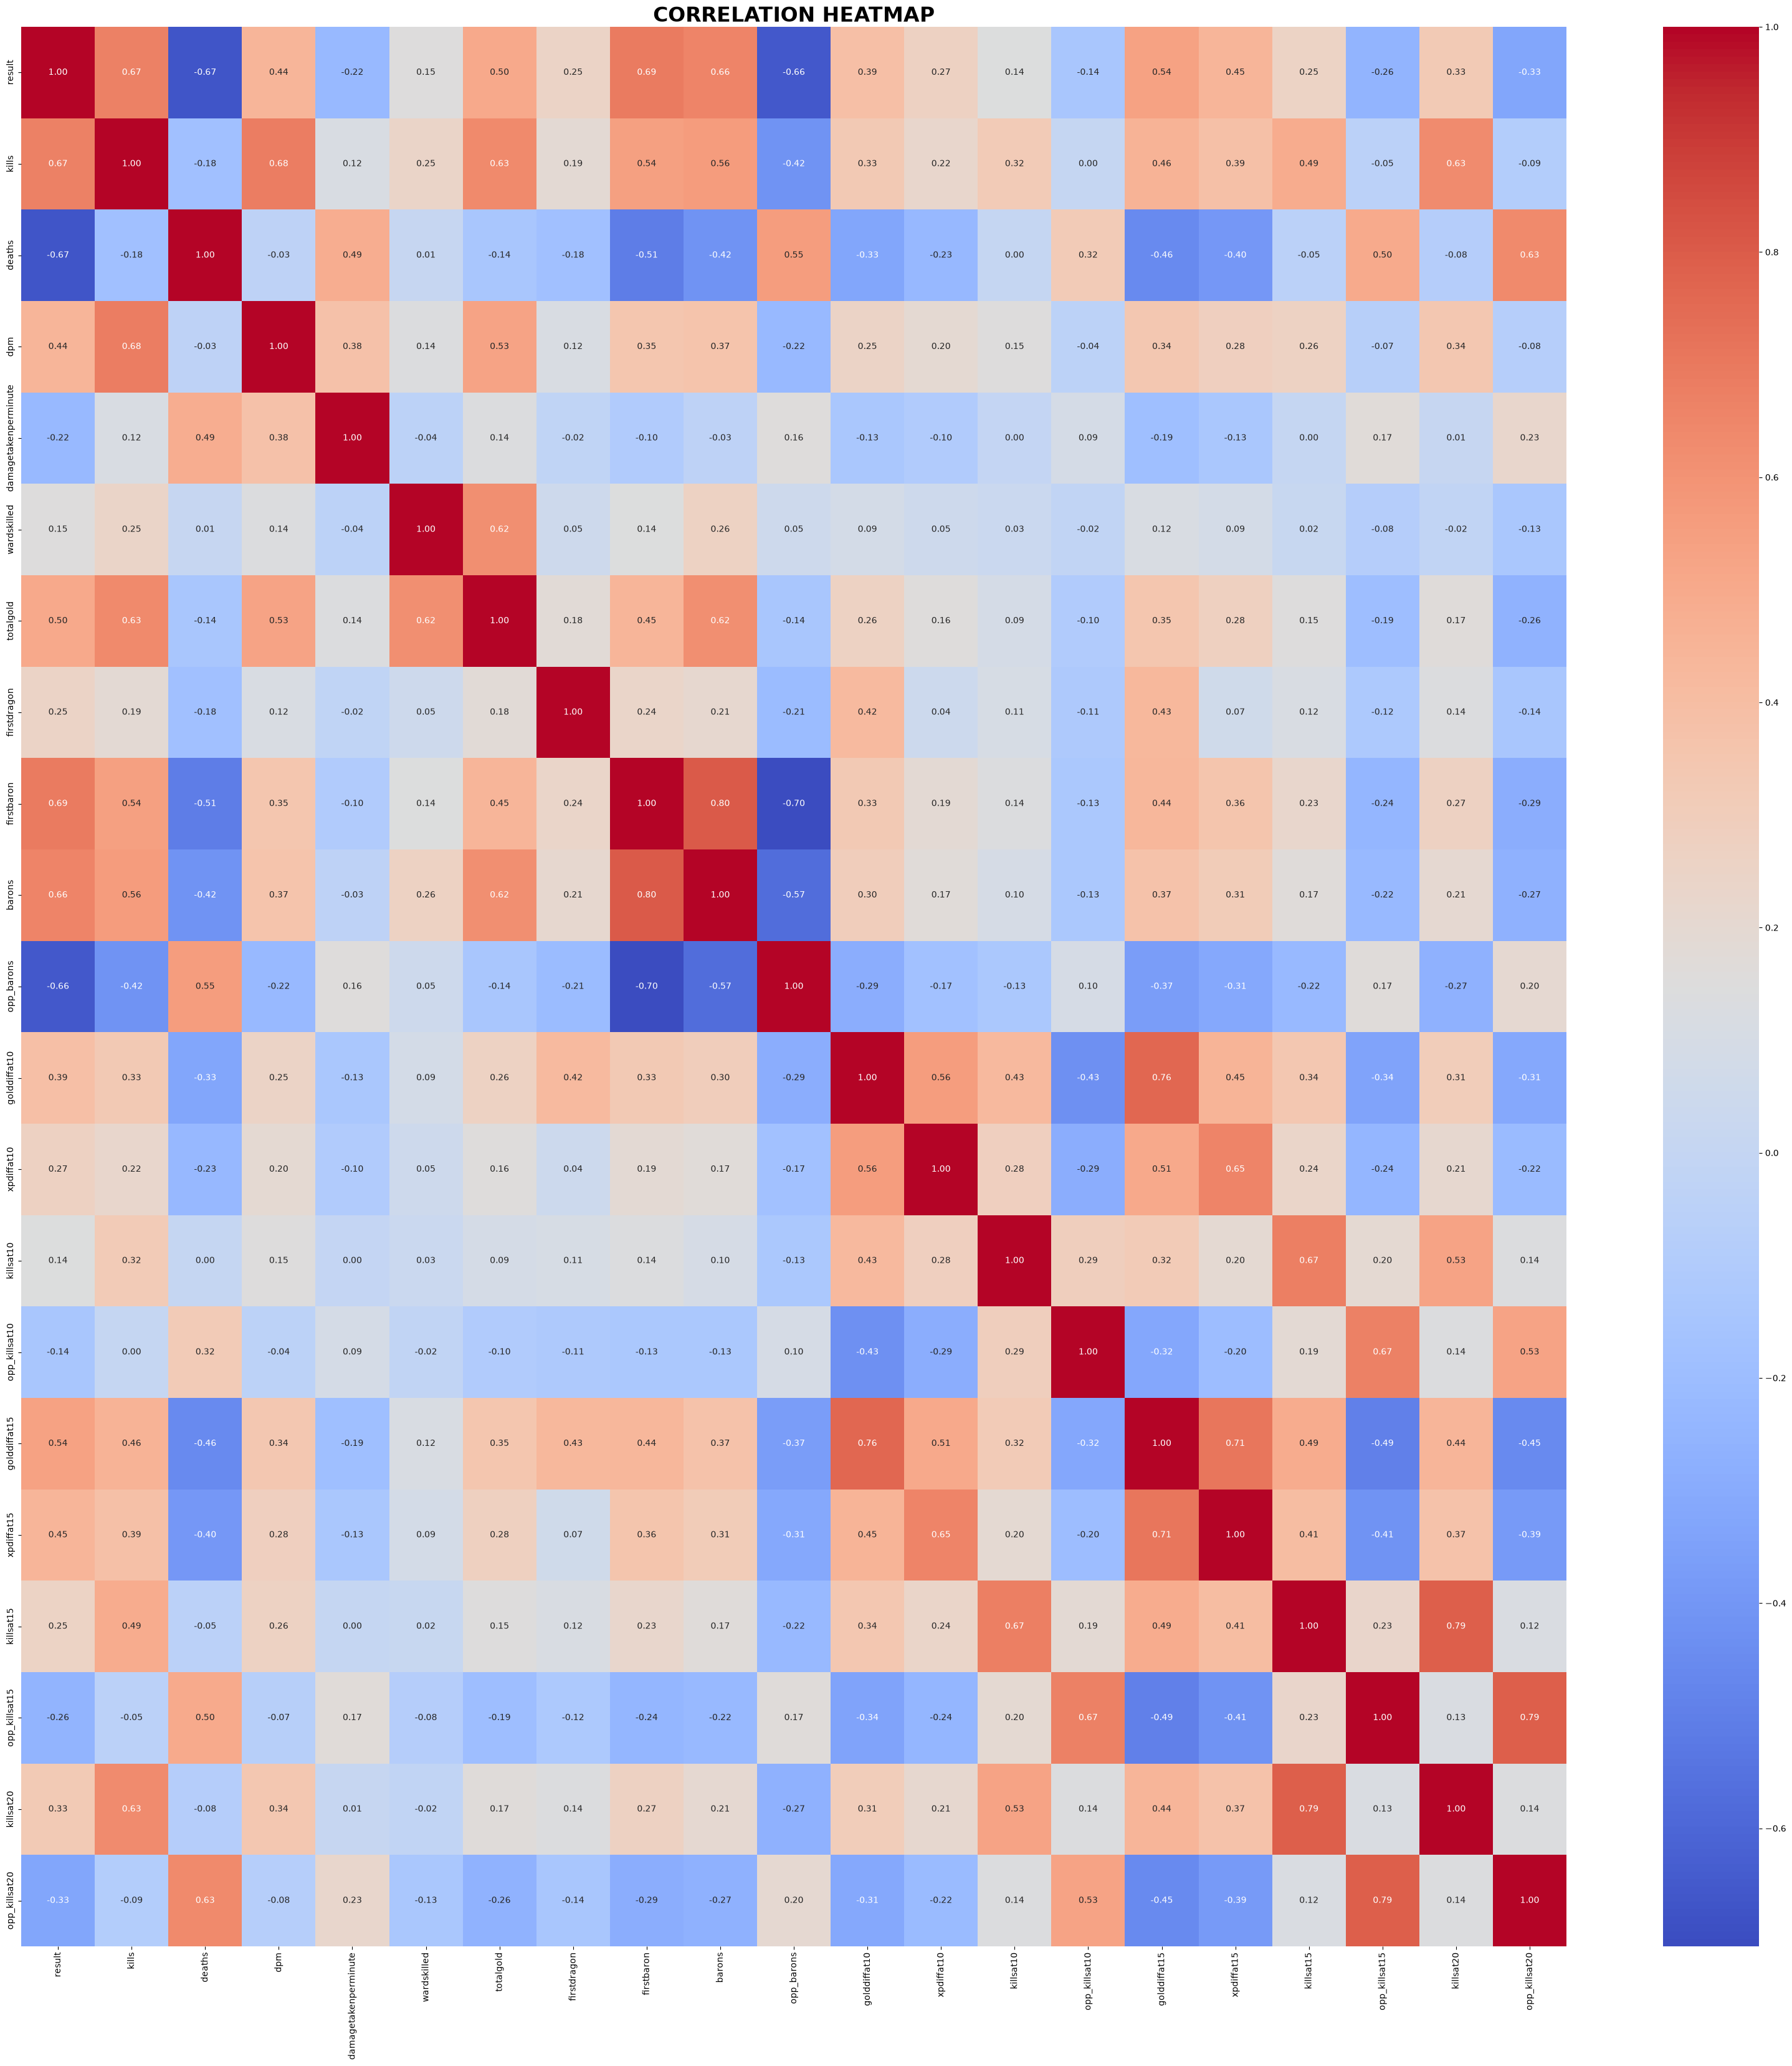

In [14]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=24, fontweight="bold")
plt.show()

In [15]:
df.to_csv("df_processed.csv", index=False)